# RC3SI — Stage 03: Feature Engineering and Feature Selection

**Goal:** turn the verified Stage 02 hourly records into transparent, leakage-aware, model-ready features and select features on **training data only**. We will perform model training and scaling in Stage 04.

**Research honesty:** `treatment_percent` describes the known irrigation assignment, **not observed physiological plant stress**. Each 2023 treatment corresponds to one physical line; this dataset cannot establish generalization across farms or new treatment replicates.

**Input:** `RC3SI_Stage02_Outputs_v1.zip` (your Colab Stage 02 export). Do not upload the old Work-mode project ZIP.

**Practical convention:** The 60% line is retained in the engineered data for plotting, but the **initial supervised binary comparison is only 100% vs 30%**. The line number, treatment percentage, split, and timestamps are *not* classifier input features. Feature selection is fit on the training partition only. We intentionally restart historical windows at each split to avoid using earlier partitions and embargo rows in validation/test features.

from IPython.display import display
## Cell 1 — Imports and reproducibility

In [1]:
from IPython.display import display
import io, json, zipfile, os, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from google.colab import files
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
pd.set_option('display.max_columns', 40)
print('Imports OK; random seed =', SEED)

Imports OK; random seed = 42


## Cell 2 — Upload your Stage 02 output ZIP

In [2]:
uploaded = files.upload()
zip_names = [name for name in uploaded if name.lower().endswith('.zip')]
assert len(zip_names) == 1, 'Please upload exactly one ZIP: RC3SI_Stage02_Outputs_v1.zip'
archive_bytes = uploaded[zip_names[0]]
with zipfile.ZipFile(io.BytesIO(archive_bytes)) as z:
    print('ZIP contents:', z.namelist())
    required = {'parma2023_hourly_with_splits.csv', 'stage02_metadata.json'}
    assert required.issubset(set(z.namelist())), 'Wrong ZIP: Stage 02 export is required'
    df = pd.read_csv(z.open('parma2023_hourly_with_splits.csv'))
    stage02_metadata = json.load(z.open('stage02_metadata.json'))
print('Imported rows/columns:', df.shape)
print('Stage 02 split embargo:', stage02_metadata['embargo_hours'], 'hours')

Saving RC3SI_Stage02_Outputs_v1.zip to RC3SI_Stage02_Outputs_v1.zip
ZIP contents: ['missing_and_ranges.csv', 'stage02_metadata.json', 'sampling_gaps.csv', 'parma2023_hourly_with_splits.csv']
Imported rows/columns: (5496, 13)
Stage 02 split embargo: 24 hours


## Cell 3 — Parse timestamps, check schema and preserve Stage 02 splits

In [3]:
df['timestamp'] = pd.to_datetime(df['timestamp'], utc=True)
df['environment_observed_at'] = pd.to_datetime(df['environment_observed_at'], utc=True)
base_features = ['soil_humidity','soil_temperature','soil_electrical_conductivity',
                 'env_co2','env_humidity','env_pressure','env_temperature']
required_cols = base_features + ['timestamp','line','treatment_percent','split']
assert set(required_cols).issubset(df.columns), 'Missing columns from Stage 02 export'
assert len(df) == 5496, 'Unexpected row count: STOP and inspect before proceeding'
assert not df.duplicated(['timestamp','line']).any(), 'Duplicate line-timestamp pairs'
assert (df['environment_observed_at'] <= df['timestamp']).all(), 'Future environmental value found'
assert set(df['split']) == {'train','validation','test','embargo_excluded'}
print(df.groupby(['split','treatment_percent']).size().unstack(fill_value=0))
print('Missing in 7 original features:', int(df[base_features].isna().sum().sum()))

treatment_percent   30    60    100
split                              
embargo_excluded     48    48    48
test                359   359   359
train              1087  1089  1091
validation          336   336   336
Missing in 7 original features: 0


## Cell 4 — Examine training-only feature ranges (no imputation yet)

In [4]:
display(df.loc[df.split == 'train', base_features].describe().T[['mean','std','min','50%','max']].round(3))

,mean,std,min,50%,max
soil_humidity,27.899,8.771,11.47,25.51,56.69
soil_temperature,24.535,2.198,19.60,24.30,32.60
soil_electrical_conductivity,478.714,303.589,53.00,404.00,1767.00
env_co2,480.087,48.457,402.00,468.00,735.00
env_humidity,58.276,17.701,18.50,55.50,97.00
env_pressure,1008.776,4.864,995.40,1009.30,1018.10
env_temperature,27.159,6.760,10.20,27.00,41.00


## Cell 5 — Define feature-building function (historical observations only)

Each line and split is put on its own **regular UTC hourly grid**. `shift(1)` means one elapsed hour, **not just the previous available row**. If an hour is missing, derived features become missing rather than pretending measurements are consecutive. Rolling features are computed from hours strictly before the target hour (`shift(1)`).

In [5]:
def build_one_group(group):
    group = group.sort_values('timestamp').set_index('timestamp')
    assert not group.index.has_duplicates
    # Missing hourly slots are represented as NaN, never forward-filled.
    complete_hours = pd.date_range(group.index.min(), group.index.max(), freq='h', tz='UTC')
    g = group.reindex(complete_hours)
    s = g['soil_humidity']
    temp = g['soil_temperature']
    for lag in (1, 3, 6):
        g[f'soil_humidity_lag_{lag}h'] = s.shift(lag)
    g['soil_humidity_change_1h'] = s - s.shift(1)
    g['soil_humidity_change_3h'] = s - s.shift(3)
    g['soil_humidity_prev_3h_mean'] = s.shift(1).rolling(3, min_periods=3).mean()
    g['soil_humidity_prev_6h_mean'] = s.shift(1).rolling(6, min_periods=6).mean()
    g['soil_humidity_prev_6h_std'] = s.shift(1).rolling(6, min_periods=6).std()
    g['soil_temperature_lag_1h'] = temp.shift(1)
    g['soil_env_temperature_gap'] = temp - g['env_temperature']
    # Preserve genuine observed records only; synthesized grid hours never enter ML.
    g = g[g['line'].notna()].copy()
    return g.rename_axis('timestamp').reset_index()

## Cell 6 — Generate features separately per physical line and split

In [6]:
parts = []
for (line, split), group in df.groupby(['line','split']):
    parts.append(build_one_group(group))
engineered = pd.concat(parts, ignore_index=True).sort_values(['timestamp','line']).reset_index(drop=True)
engineered['line'] = engineered['line'].astype(int)
engineered['treatment_percent'] = engineered['treatment_percent'].astype(int)
new_features = [c for c in engineered.columns if c not in df.columns]
model_features = base_features + new_features
print('Engineered rows (before dropping history gaps):', len(engineered))
print('New feature count:', len(new_features))
print(new_features)
assert len(engineered) == len(df)
assert all(c not in model_features for c in ['line','split','treatment_percent','timestamp'])

Engineered rows (before dropping history gaps): 5496
New feature count: 10
['soil_humidity_lag_1h', 'soil_humidity_lag_3h', 'soil_humidity_lag_6h', 'soil_humidity_change_1h', 'soil_humidity_change_3h', 'soil_humidity_prev_3h_mean', 'soil_humidity_prev_6h_mean', 'soil_humidity_prev_6h_std', 'soil_temperature_lag_1h', 'soil_env_temperature_gap']


## Cell 7 — Measure unavailable history (do not globally fill it)

In [7]:
missing_by_split = engineered.groupby('split')[new_features].apply(lambda x: x.isna().mean().mul(100).round(2))
display(missing_by_split.T)
print('Rows with all engineered and original features available:', int(engineered[model_features].notna().all(axis=1).sum()))

split,embargo_excluded,test,train,validation
soil_humidity_lag_1h,4.17,0.28,0.12,0.30
soil_humidity_lag_3h,12.50,0.84,0.31,0.89
soil_humidity_lag_6h,25.00,1.67,0.58,1.79
soil_humidity_change_1h,4.17,0.28,0.12,0.30
soil_humidity_change_3h,12.50,0.84,0.31,0.89
soil_humidity_prev_3h_mean,12.50,0.84,0.31,0.89
soil_humidity_prev_6h_mean,25.00,1.67,0.58,1.79
soil_humidity_prev_6h_std,25.00,1.67,0.58,1.79
soil_temperature_lag_1h,4.17,0.28,0.12,0.30
soil_env_temperature_gap,0.00,0.00,0.00,0.00


Rows with all engineered and original features available: 5405


## Cell 8 — Make complete-history modeling subset; preserve all source records for audit

For this beginner baseline we use complete-history cases and report the count excluded. Missing hourly readings are not interpolated, and no later observation is used to fill an earlier one. Missingness-aware modeling can be investigated later.

In [8]:
model_df = engineered.loc[engineered[model_features].notna().all(axis=1) &
                          engineered['split'].isin(['train','validation','test'])].copy()
print('Original rows by split:')
print(df.groupby('split').size())
print('Complete-history modeling rows by split:')
print(model_df.groupby(['split','treatment_percent']).size().unstack(fill_value=0))
print('Remaining samples:', len(model_df))
assert not model_df[model_features].isna().any().any()
assert model_df['split'].isin(['train','validation','test']).all()

Original rows by split:
split
embargo_excluded     144
test                1077
train               3267
validation          1008
dtype: int64
Complete-history modeling rows by split:
treatment_percent   30    60    100
split                              
test                353   353   353
train              1081  1083  1084
validation          330   330   330
Remaining samples: 5297


## Cell 9 — Plot lagged/current soil humidity (visual QC)

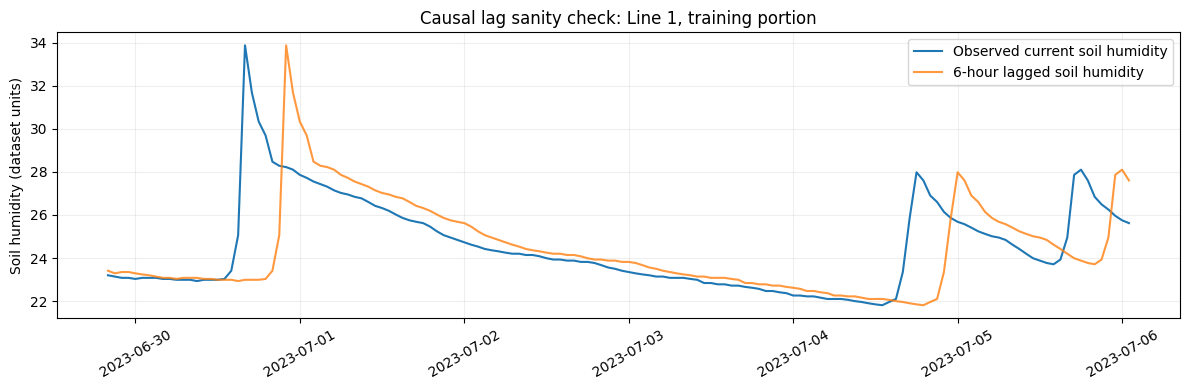

In [9]:
example = model_df[(model_df['line'] == 1) & (model_df['split'] == 'train')].head(150)
fig, ax = plt.subplots(figsize=(12,4))
ax.plot(example.timestamp, example.soil_humidity, label='Observed current soil humidity')
ax.plot(example.timestamp, example.soil_humidity_lag_6h, label='6-hour lagged soil humidity', alpha=.8)
ax.set_title('Causal lag sanity check: Line 1, training portion')
ax.set_ylabel('Soil humidity (dataset units)')
ax.legend(); ax.grid(alpha=.2); plt.xticks(rotation=30); plt.tight_layout(); plt.show()

## Cell 10 — Correlation heatmap (training records only)

Correlations can be informative but do not establish causal effects. We use *training* records only to avoid data snooping into validation/test.

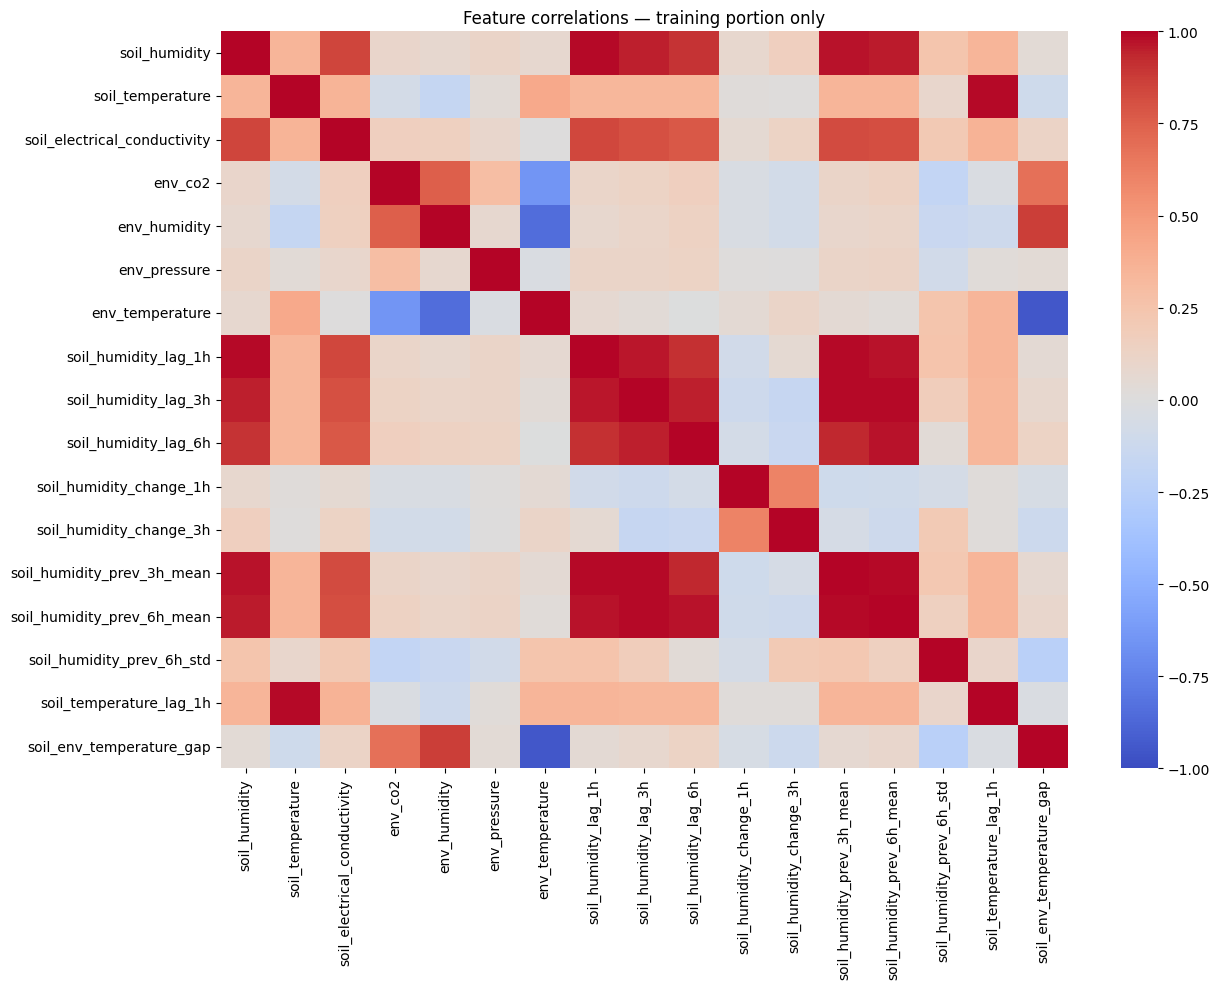

In [10]:
train_all_lines = model_df[model_df.split == 'train']
plt.figure(figsize=(13,10))
sns.heatmap(train_all_lines[model_features].corr(), cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Feature correlations — training portion only')
plt.tight_layout(); plt.show()

## Cell 11 — Declare honest binary labels and prohibit identifier leakage

`0 = 100% reference irrigation line`, `1 = 30% reduced irrigation line`. This is a **treatment-pattern** experiment, not a measured plant-stress diagnosis. The 60% line is reserved for future descriptive or multiclass work, not relabeled as a verified stress class.

In [11]:
binary = model_df[model_df['treatment_percent'].isin([100,30])].copy()
binary['target'] = (binary['treatment_percent'] == 30).astype(int)
for split in ['train','validation','test']:
    counts = binary.loc[binary.split == split, 'target'].value_counts().to_dict()
    print(split, 'class counts:', counts)
    assert set(counts) == {0,1}, f'{split} is missing a class'
assert not set(['line','treatment_percent','split','timestamp','target','environment_observed_at']).intersection(model_features)
print('Predictors exclude line, treatment, timestamps, target, and split: OK')

train class counts: {0: 1084, 1: 1081}
validation class counts: {0: 330, 1: 330}
test class counts: {0: 353, 1: 353}
Predictors exclude line, treatment, timestamps, target, and split: OK


## Cell 12 — Remove constant predictors using *training only*

In [12]:
train = binary[binary.split == 'train']
X_train_all = train[model_features]
y_train = train['target']
var_filter = VarianceThreshold(threshold=0.0)
var_filter.fit(X_train_all)
nonconstant = list(X_train_all.columns[var_filter.get_support()])
removed = sorted(set(model_features)-set(nonconstant))
print('Candidate features:', len(model_features))
print('Removed constant training features:', removed)
print('Remaining:', len(nonconstant))
assert nonconstant, 'No nonconstant features remain'

Candidate features: 17
Removed constant training features: []
Remaining: 17


## Cell 13 — Rank features using mutual information on the *training set only*

Mutual information is descriptive here: it can reward features that identify a physical line. It **cannot** establish that any feature diagnoses physiological plant stress or generalizes to an unseen farm. A fixed random seed makes the estimator repeatable.

In [13]:
# Mutual information uses neighbor distances: scale training X only for its ranking.
mi_scaler = StandardScaler()
X_train_scaled = mi_scaler.fit_transform(train[nonconstant])
mi_values = mutual_info_classif(X_train_scaled, y_train, random_state=SEED, n_neighbors=5)
ranked = pd.DataFrame({'feature': nonconstant, 'training_mutual_info':mi_values})
ranked = ranked.sort_values(['training_mutual_info','feature'], ascending=[False,True]).reset_index(drop=True)
display(ranked.round(5))

,feature,training_mutual_info
0,soil_humidity_lag_1h,0.31227
1,soil_humidity_lag_6h,0.31104
2,soil_humidity,0.30971
3,soil_humidity_lag_3h,0.30967
4,soil_humidity_prev_3h_mean,0.27271
5,soil_humidity_prev_6h_mean,0.26725
6,soil_electrical_conductivity,0.21754
7,soil_humidity_change_3h,0.06914
8,soil_humidity_change_1h,0.03616
9,soil_temperature,0.03216


## Cell 14 — Plot ranked feature importance (training-only selection)

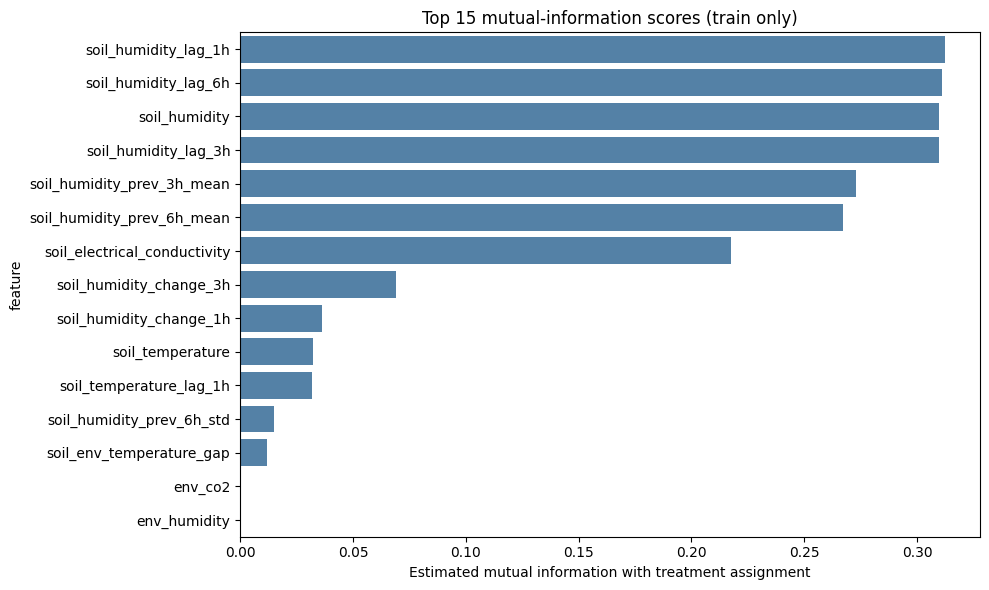

In [14]:
plt.figure(figsize=(10, 6))
sns.barplot(data=ranked.head(15), y='feature', x='training_mutual_info', color='steelblue')
plt.title('Top 15 mutual-information scores (train only)')
plt.xlabel('Estimated mutual information with treatment assignment')
plt.tight_layout(); plt.show()

## Cell 15 — Select top features without consulting validation/test

For the Stage 04 baseline we predefine **top 10** (or fewer if fewer survive). Stage 04 can compare using all predictors as a transparent control. These are *not* test-optimized choices.

In [15]:
K_FEATURES = min(10, len(nonconstant))
selected_features = ranked.head(K_FEATURES)['feature'].tolist()
print('Selected features:')
for i, col in enumerate(selected_features,1):
    print(f'{i:2d}. {col}')
assert len(selected_features)==K_FEATURES
assert all(c in model_features for c in selected_features)

Selected features:
 1. soil_humidity_lag_1h
 2. soil_humidity_lag_6h
 3. soil_humidity
 4. soil_humidity_lag_3h
 5. soil_humidity_prev_3h_mean
 6. soil_humidity_prev_6h_mean
 7. soil_electrical_conductivity
 8. soil_humidity_change_3h
 9. soil_humidity_change_1h
10. soil_temperature


## Cell 16 — Final leakage checks and reproducibility notes

In [16]:
# Each historical feature is calculated inside a single (line, split) group.
# Count examples per split: no treatment IDs as input, no embargo rows in model.
assert not binary[['timestamp','line','split']].duplicated().any()
assert not binary[model_features].isna().any().any()
assert set(binary['split']) == {'train','validation','test'}
print('Excluded embargo rows from modeling: OK')
print('Model contains only complete, observed-history examples: OK')
print('Selected training-only feature list:', len(selected_features))
print('CAVEAT: same field, single year, one physical line per treatment.')
print('Not established: independent stress labels, early-warning onset, causal effect, cross-farm generalization.')

Excluded embargo rows from modeling: OK
Model contains only complete, observed-history examples: OK
Selected training-only feature list: 10
CAVEAT: same field, single year, one physical line per treatment.
Not established: independent stress labels, early-warning onset, causal effect, cross-farm generalization.


## Cell 17 — Export Stage 03 outputs for Stage 04

The ZIP stores engineered **raw/unscaled** features and the training-selected columns. In Stage 04, scalers/imputers/classifiers must be fit on the training partition *within each model pipeline*. Do not fit on all three partitions. `line` and `treatment_percent` are saved for audit only, not as predictors.

In [17]:
export_dir = Path('rc3si_stage03_outputs')
export_dir.mkdir(exist_ok=True)
binary.to_csv(export_dir/'parma2023_binary_engineered.csv', index=False)
model_df.to_csv(export_dir/'parma2023_all_treatments_engineered.csv', index=False)
ranked.to_csv(export_dir/'feature_ranking_training_only.csv', index=False)
manifest = {
 'project':'RC3SI', 'stage':'03 Feature Engineering and Selection',
 'source_archive':zip_names[0],
 'classification_target':'100% (0) vs 30% (1) irrigation-assignment pattern, NOT observed physiological stress',
 'features_all':model_features,
 'features_selected_training_only':selected_features,
 'selected_k':K_FEATURES,
 'lag_policy':'regular hourly grid per line and split; shift/rolling past-only, no interpolation',
 'split_policy':'Stage 02 chronological split retained; embargo excluded; histories restart within split',
 'feature_ranking':'training-only StandardScaler + sklearn mutual_info_classif (random_state=42, n_neighbors=5)',
 'feature_scaling_for_models':'NOT APPLIED; fit sklearn Pipeline scaler on training partition in Stage 04',
 'limitations':['one line per treatment confounds treatment with line',
                'single field and year 2023', 'no verified physiological-stress ground truth',
                'no independent treatment replication or causal counterfactual'],
 'counts_by_split_binary':{str(k):int(v) for k,v in binary.groupby('split').size().items()}
}
(export_dir/'stage03_manifest.json').write_text(json.dumps(manifest, indent=2))
zip_output='RC3SI_Stage03_Outputs_v1.zip'
with zipfile.ZipFile(zip_output,'w',zipfile.ZIP_DEFLATED) as z:
    for path in sorted(export_dir.iterdir()):
        z.write(path, path.name)
print('Exported:', zip_output)
print('Files:', [p.name for p in export_dir.iterdir()])
print('DOWNLOAD THIS ZIP and upload it to our chat along with your executed notebook.')
files.download(zip_output)

Exported: RC3SI_Stage03_Outputs_v1.zip
Files: ['stage03_manifest.json', 'feature_ranking_training_only.csv', 'parma2023_all_treatments_engineered.csv', 'parma2023_binary_engineered.csv']
DOWNLOAD THIS ZIP and upload it to our chat along with your executed notebook.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>